In [ ]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import scipy.special as scp
from itertools import product
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
import scipy.stats as stats
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

from classes import Agent, MultiArmedBandit, World
from utilities import run_simulation, create_long_df_multiple_levers
from statannotations.Annotator import Annotator

def plot_results(dataframe, matrices, pars, labels,dpi=200):
	
	##############################
	# Plot experimental setup
	##############################

	if False:
		fig, axes = plt.subplots(1,3,figsize=(12,3))

		g = sns.heatmap(ax=axes[0], data=pars["Rho"][:,:,0], annot=True, cmap="gray")
		# g = sns.heatmap(ax=axes[1], data=pars["Rho"][:,:,1], annot=True, cmap="gray")
		g.yaxis.set_ticklabels(labels["reward_legend_labels"],rotation=45)
		g.xaxis.set_ticklabels(labels["state_legend_labels"],rotation=45)

		g = sns.heatmap(np.array(pars["utility_1"])[pars["training_protocol"],:].T, cmap="gray",ax=axes[1])
		g.yaxis.set_ticklabels(labels["reward_legend_labels"][:-1],rotation=45)
		g.set_xlabel("trial")

		g = sns.heatmap(np.array(pars["utility_2"])[pars["training_protocol"],:].T, cmap="gray",ax=axes[2])
		g.yaxis.set_ticklabels(labels["reward_legend_labels"][:-1],rotation=45)
		g.set_xlabel("trial")
		for ax, title in zip(axes, ["p(reward|state) Training", "Utility Group 1", "Utility Group 2"]):
			ax.set_title(title)


	##############################
	# Plot devaluation sensitivity
	##############################

	if True:
		df = dataframe.groupby(by=["experimental_group","sim","phase","t"])["action"].value_counts(normalize=True)
		relative_action = (df[:,:,"extinction",0])/(df[:,:,"training",0])

		fig, g = plt.subplots(1,1, figsize=(4,3),dpi=200)
		plt.subplots_adjust(wspace=0.4)
		plot_df = relative_action.reset_index().astype({"experimental_group":"category"}).query("action == 0")
		g = sns.barplot(data=plot_df, x="experimental_group", y="proportion", order=[1,0],palette="Grays_r", linewidth=0.5, edgecolor="black")
		g.xaxis.set_ticklabels(["O1 devalued", "O2 devalued"],rotation=0, fontsize=16)
		g.set_ylabel("Lever press\n(extinction/training)", fontsize=16)
		g.set_xlabel(None)
		g.set_ylim((0,1.2))


		annotator = Annotator(g, [(0,1)], data=plot_df, x="experimental_group", y="proportion", order=[1,0])
		annotator.configure(test="Mann-Whitney", text_format="star", loc="inside")
		annotator.apply_and_annotate()


	############################################
	# Plot correlation of rate of lever pressing 
	# vs trial at which context switch inferred
	############################################

	if True:
		df = dataframe.copy()
		df["context_c"] = df["context_c"] - pars["n_blocks_train"]*pars["block_length"]                                  # center trial at which context switch inferred
		df = df.groupby(by=["experimental_group","sim","phase","t","context_c"])[["action"]].value_counts(normalize=True)  # count number of time action 0 was executed
		df = ((df[:,:,"extinction",0,:])/(df[:,:,"training",0,:])).reset_index().query("action == 0")                      # normalize relative to training phase
		df.loc[(df["context_c"] > pars["block_length"]) | (df["context_c"] < 0),"context_c"] = np.nan


		d = df[["experimental_group", "proportion","context_c"]].dropna()
		plt.figure(dpi=200, figsize=(4,3))
		plt.subplots_adjust(wspace=0.4)
		plt.subplot(1,1,1)
		# r_g1,p_g1 = pearsonr(d.query("experimental_group==0")["context_c"], d.query("experimental_group==0")["proportion"])
		# r_g2,p_g2 = pearsonr(d.query("experimental_group==1")["context_c"], d.query("experimental_group==1")["proportion"])
		r_all,p_all = pearsonr(d["context_c"], d["proportion"])

		p = 0.05
		# p_g1 = p if p_g1 < p else p_g1
		# p_g2 = p if p_g2 < p else p_g2
		p_all = fr"$p<{p}$" if p_all < p else fr"$p={p_all.round(2)}$"

		# g = sns.regplot(data=df.query("experimental_group==0"), y="proportion",x="context_c", ci=95, scatter_kws={"alpha":0.5},label=fr"O2 devalued Pearson $\rho$: {r_g1.round(2)}, p<{p_g1}")
		# g = sns.regplot(data=df.query("experimental_group==1"), y="proportion",x="context_c", ci=95, scatter_kws={"alpha":0.5},label=fr"O1 devalued Pearson $\rho$: {r_g2.round(2)}, p<{p_g2}")
		
		
		g = sns.regplot(data=df, y="proportion",x="context_c", ci=95,
		                scatter_kws={"s":2, "color":"black"},
						line_kws = {"color":"black"},
						)

		g.legend(labels = [fr"$\rho^2$: {r_all.round(2)}" + "\n" +  p_all], frameon=False, markerscale=0,fontsize=12)
		g.set_xlabel("Trial when context 2 \n  posterior > 0.5", fontsize=16)
		g.set_ylabel("Lever press \n (extinction/training)", fontsize=16)


	################################
	# PLot action frequency in each block
	################################

	if False:
		df = (dataframe.groupby(by=["experimental_group","sim","block","t"])["action"].value_counts()).reset_index()
		plt.figure(figsize=(7,3))

		plt.subplot(1,2,1)
		plt.title("Group where noncontingent\n O2 devalued", fontsize=14)
		g = sns.pointplot(data=df.astype({"experimental_group":"category"}).query("experimental_group==0"), x="block",y="count",hue="action")
		g.set_ylabel("Action count", fontsize=14)
		g.legend(handles=g.get_legend_handles_labels()[0], labels=labels["action_legend_labels"], fontsize=14)

		plt.subplot(1,2,2)
		g = sns.pointplot(data=df.query("experimental_group==1"), x="block",y="count",hue="action")
		g.set_ylabel("Action count", fontsize=14)
		g.legend(handles=g.get_legend_handles_labels()[0], labels=labels["action_legend_labels"], fontsize=14)
		plt.title("Group where contingent\n O1 devalued", fontsize=14)

		plt.subplots_adjust(wspace=0.3)

	#############################
	#  Context posterior
	#############################

	if False:
		plt.figure(figsize=(7,3))
		plt.subplot(1,2,1)
		sns.lineplot(data=dataframe.query("t==1 & experimental_group==0"), x="tau", y="posterior_context_c0", errorbar="se", label="Context 1")
		g = sns.lineplot(data=dataframe.query("t==1 & experimental_group==0"), x="tau", y="posterior_context_c1", errorbar="se", label="Context 2")
		g.set_ylabel("Context posterior", fontsize=14)
		plt.title("Group where noncontingent\n O2 devalued", fontsize=14)

		plt.subplot(1,2,2)
		g = sns.lineplot(data=dataframe.query("t==1 & experimental_group==1"), x="tau", y="posterior_context_c0", errorbar="se", label="Context 1")
		g = sns.lineplot(data=dataframe.query("t==1 & experimental_group==1"), x="tau", y="posterior_context_c1", errorbar="se", label="Context 2")
		g.set_ylabel("Context posterior", fontsize=14)
		plt.title("Group where contingent\n O1 devalued", fontsize=14)

		plt.subplots_adjust(wspace=0.3)


	#############################
	#  Learned reward contingencies
	#############################

	if False:
		try:
			plt.figure(figsize=(11,4))
			plt.subplot(1,2,1)
			g = sns.heatmap(matrices["reward_generation_matrix"][:,:,0],annot=True, cmap="gray")
			g.yaxis.set_ticklabels(labels["reward_legend_labels"],rotation=45, fontsize=14)
			g.xaxis.set_ticklabels(labels["state_legend_labels"],rotation=45, fontsize=14,)
			plt.subplot(1,2,2)
			g = sns.heatmap(matrices["reward_generation_matrix"][:,:,1],annot=True, cmap="gray")
			g.yaxis.set_ticklabels(labels["reward_legend_labels"],rotation=45, fontsize=14)
			g.xaxis.set_ticklabels(labels["state_legend_labels"],rotation=45, fontsize=14)
		except:
			print("can't plot learned reward contingencies, no matrices")

	#############################
	#  Learned policy prior
	#############################

	if False:
		try:
			plt.figure(figsize=(4,4))
			plt.subplot(1,1,1)
			plt.title("Action Prior", fontsize=14)
			g = sns.heatmap(matrices["policy_prior_matrix"],annot=True, cmap="gray")
			g.yaxis.set_ticklabels(labels["action_legend_labels"],rotation=45, fontsize=14)
			g.xaxis.set_ticklabels(["context 1", "context 2"],rotation=45, fontsize=14)
		except:
			print("can't plot learned policy prior, no matrices")	


	#############################
	#  Reinforcement schedule
	#############################
	if False:
		plt.figure()
		df = dataframe.groupby(by=["sim", "phase", "t"])["reward"].value_counts().reset_index()
		sns.barplot(data = df.query("phase == 'training' & t == 1"), y="count",hue="reward")




### Two lever experiment

C:\Users\siahr\AppData\Local\Temp\ipykernel_11084\2592270305.py:3: DeprecationWarning: This function is deprecated. Please call randint(1, 1000000 + 1) instead
  for seed in np.random.random_integers(1000000, size=1):
c:\Users\siahr\Documents\repositories\ContextualSUD\notebooks\utilities.py:170: OptimizeWarning: Covariance of the parameters could not be estimated
  exponential_params, policy_pcov = curve_fit(exponential, t[10:], q_action[10:], p0=[1., switch, 0.])
c:\Users\siahr\Documents\repositories\ContextualSUD\notebooks\utilities.py:166: OptimizeWarning: Covariance of the parameters could not be estimated
  policy_params, policy_pcov = curve_fit(sigmoid, t[10:], q_action[10:], p0=[1., 1., switch, 0.])
C:\Users\siahr\AppData\Local\Temp\ipykernel_11084\1701129328.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.barplot(data=plot_df, 

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

1 vs. 0: Mann-Whitney-Wilcoxon test two-sided, P_val:3.825e-09 U_stat=5.100e+01


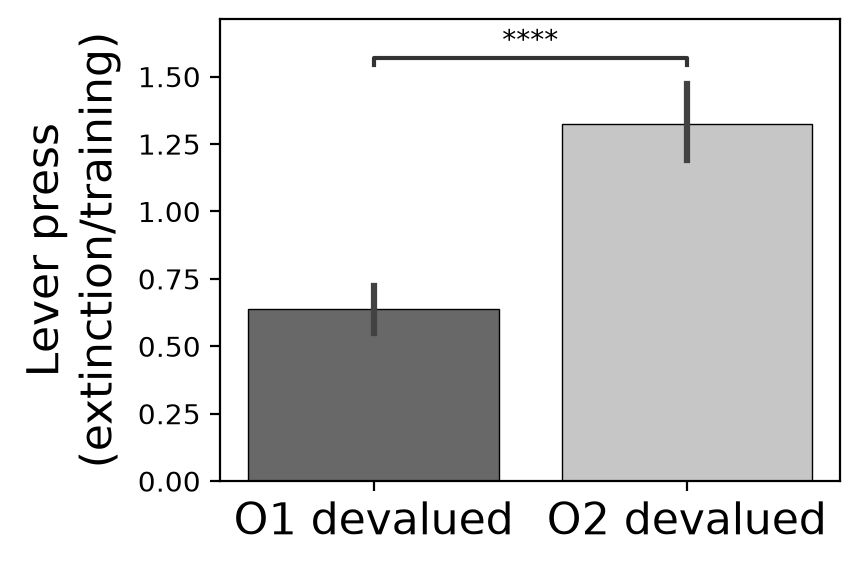

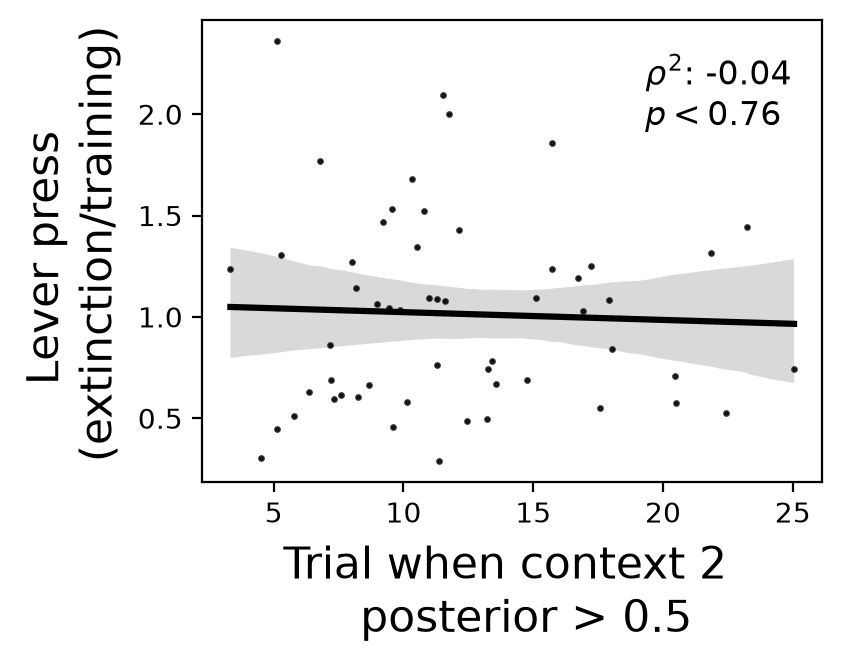

In [6]:
np.random.seed(10)

for seed in np.random.random_integers(1000000, size=1):
	
	pars = {}
	pars["reps"] = 30
	pars["n_blocks_train"] = 10
	pars["n_blocks_extinction"] = 1
	pars["block_length"] = 30
	pars["switch"] = pars["n_blocks_train"]*pars["block_length"]
	pars["na"]=3  								# left, right, nothing
	pars["nr"]=4  								# O1, O2, ~O, init
	pars["nb"] = pars["na"]-1
	pars["ns"]=pars["na"]+1					    # L1, L2, ~L, init
	pars["nc"]=2
	pars["n_train"] = pars["n_blocks_train"]*pars["block_length"]
	pars["n_extinction"] = pars["n_blocks_extinction"]*pars["block_length"]
	pars["training_protocol"] = [0]*pars["n_train"] + [1]*pars["n_extinction"]
	pars["TAU"] = pars["n_train"] + pars["n_extinction"]
	pars["T"] = 2
	pars["rho_noncontingent"] = 0
	pars["context_volatility"]=0.99
	pars["h"]=10
	pars["habit_exception"] = 2
	
	p = 0.45
	r = 0.05
	pars["utility_1"] = [[0.45,0.45, 0.1], [p, r, 1-p-r]]
	pars["utility_2"] = [[0.45,0.45, 0.1], [r, p, 1-p-r]]

	rho =0.8
	pars["Rho"] = np.stack([[[rho  , 0.0, 0.0, 0.0],
					[0.0, rho  , 0.0, 0.0],
					[1-rho, 1-rho, 1.0, 0.0],
					[0.0, 0.0, 0.0, 1.0]],
					[[0, 0, 0, 0],
					[0, 0, 0, 0],
					[1, 1, 1, 0],
					[0, 0, 0, 1]]], axis=-1)


	pars["reward_mapping"] = {"outcome_1":0, "outcome_2":1, "no_reward":2, "initial_state":3}
	pars["action_mapping"] = {"lever_press_1":0, "lever_press_2":1, "no_lever_press":2}

	long_dfs = []
	sim = 0                             
	srm = np.zeros([pars["nr"], pars["ns"], pars["nc"], pars["reps"]*2])   # log for reward generation matrix
	pcm = np.zeros([pars["na"], pars["nc"], pars["reps"]*2])      # log for policy prior matrix

	for rep in range(pars["reps"]):
		for group, util in enumerate([pars["utility_1"], pars["utility_2"]]):

			pars["utility"] = np.zeros([pars["TAU"],pars["nr"]])
			pars["utility"][:pars["n_train"],:-1] = np.array(util[0])[None, :]
			pars["utility"][pars["n_train"]:,:-1] = np.array(util[1])[None, :]
			world, srm[:,:,:,sim], pcm[:,:,sim] = run_simulation(**pars)
			
			# create dataframe for this simulation
			df_pars = pars.copy()
			df_pars["rep"] = rep
			df_pars["group"] = group
			df_pars["sim"] = sim

			long_df = create_long_df_multiple_levers(world, df_pars)
			long_dfs.append(long_df)
			
			sim += 1

	# create whole simulation run dataframe
	dataframe = pd.concat(long_dfs)
	matrices = {"reward_generation_matrix": srm.mean(axis=-1), "policy_prior_matrix": pcm.mean(axis=-1)}
	pars["training_protocol"] = world.environment.training_protocol
	
	# plot results
	l = {"action_legend_labels":["Lever 1 press", "Lever 2 Press", "No lever press"],
		"state_legend_labels":["Lever 1 press", "Lever 2 Press", "No lever press","init state"],
		"reward_legend_labels":["O1","O2","no reward", "init state reward"]}


	plot_results(dataframe, matrices, pars, l)

### Single lever experiment

c:\Users\siahr\Documents\repositories\ContextualSUD\notebooks\utilities.py:170: OptimizeWarning: Covariance of the parameters could not be estimated
  exponential_params, policy_pcov = curve_fit(exponential, t[10:], q_action[10:], p0=[1., switch, 0.])
C:\Users\siahr\AppData\Local\Temp\ipykernel_11084\1701129328.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.barplot(data=plot_df, x="experimental_group", y="proportion", order=[1,0],palette="Grays_r", linewidth=0.5, edgecolor="black")
C:\Users\siahr\AppData\Local\Temp\ipykernel_11084\1701129328.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.xaxis.set_ticklabels(["O1 devalued", "O2 devalued"],rotation=0, fontsize=16)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

1 vs. 0: Mann-Whitney-Wilcoxon test two-sided, P_val:2.837e-01 U_stat=3.770e+02


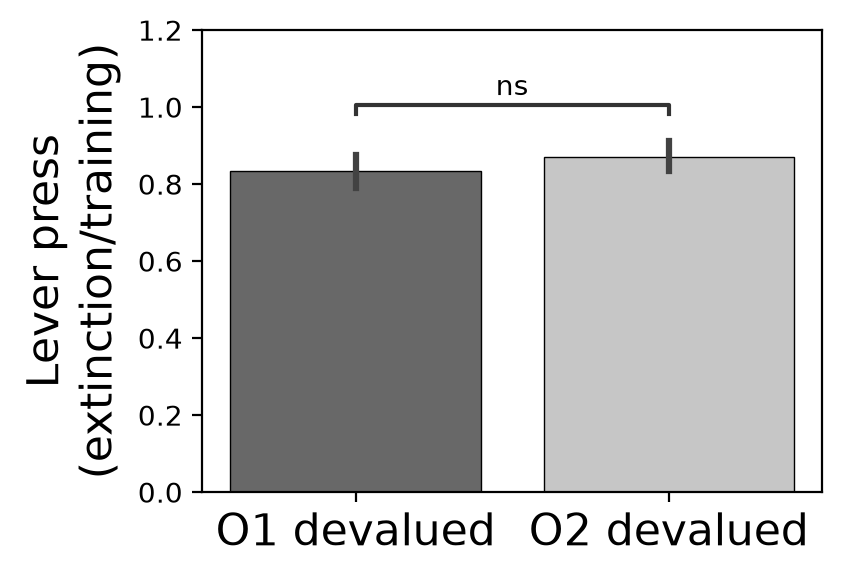

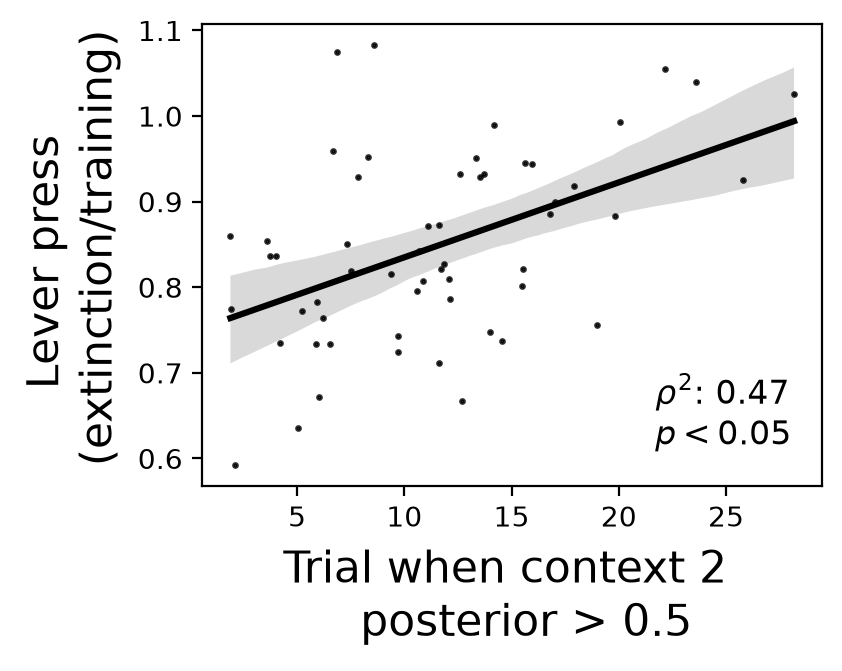

In [7]:

np.random.seed(10)

for seed in np.random.randint(1, 1000000 + 1, size=1):
	
	"""          SIMULATION PARAMETER SETUP         """
	pars = {}
	pars["reps"] = 30
	pars["n_blocks_train"] = 10 
	pars["n_blocks_extinction"] = 1
	pars["block_length"] = 30 
	pars["switch"] = pars["n_blocks_train"]*pars["block_length"]
	pars["debug"] = False
	pars["n_train"] = pars["n_blocks_train"]*pars["block_length"]
	pars["n_extinction"] = pars["n_blocks_extinction"]*pars["block_length"]
	pars["training_protocol"] = [0]*pars["n_train"] + [1]*pars["n_extinction"]

	pars["TAU"] = pars["n_train"] + pars["n_extinction"]
	pars["T"] = 2
	pars["nr"] = 4
	pars["na"] = 2
	pars["npi"] = pars["na"]**pars["T"]
	pars["ns"] = pars["na"]+1
	pars["nc"] = 2
	pars["bias"] = 0
	pars["reward_mapping"] = {"outcome_1":0, "outcome_2":1, "no_reward":2, "initial_state":3}
	pars["action_mapping"] = {"lever_press":0, "no_lever_press":1}

	pars["context_volatility"]=0.99
	pars["h"]=10
	pars["habit_exception"] = 1
	r = 0.05
	p = 0.45
	pars["utility_1"] = [[0.45,0.45, 0.1], [p, r, 1-p-r]]
	pars["utility_2"] = [[0.45,0.45, 0.1], [r, p, 1-p-r]]
	pars["rho_noncontingent"] = 0.2
	rho = 0.8
	pars["Rho"] = np.stack([[[ rho, 0.0, 0.0],
					 [  0.0, 0.0, 0.0],
					 [1-rho, 1.0, 0.0],
					 [  0.0, 0.0, 1.0]],
					[[0, 0, 0],
					 [0, 0, 0],
					 [1, 1, 0],
					 [0, 0, 1]
					]], axis=-1)

	long_dfs = []
	sim = 0                             
	srm = np.zeros([pars["nr"],pars["ns"],pars["nc"],pars["reps"]*2])   # log for reward generation matrix
	pcm = np.zeros([pars["na"],pars["nc"],pars["reps"]*2])      # log for policy prior matrix

	for rep in range(pars["reps"]):
		for group, util in enumerate([pars["utility_1"],pars["utility_2"]]):

			# define utility for each group
			pars["utility"] = np.zeros([pars["TAU"],pars["nr"]])
			pars["utility"][:pars["n_train"],:-1] = np.array(util[0])[None, :]
			pars["utility"][pars["n_train"]:,:-1] = np.array(util[1])[None, :]

			# run simulation
			world, srm[:,:,:,sim], pcm[:,:,sim] = run_simulation(**pars)

			# create dataframe for this simulation
			df_pars = pars.copy()
			df_pars["rep"] = rep
			df_pars["group"] = group
			df_pars["sim"] = sim

			long_df = create_long_df_multiple_levers(world, df_pars)
			long_dfs.append(long_df)
			
			sim += 1

	# create whole simulation run dataframe
	dataframe = pd.concat(long_dfs)
	matrices = {"reward_generation_matrix": srm.mean(axis=-1), "policy_prior_matrix": pcm.mean(axis=-1)}
	pars["training_protocol"] = world.environment.training_protocol

	
	# dataframe, matrices, pars = run_all_simulations(**pars)

	l = {"action_legend_labels":["Lever press", "No lever press"],
		"state_legend_labels":["Lever press", "No lever press","init state"],
		"reward_legend_labels":["O1","O2","no reward", "init state reward"]}

	plot_results(dataframe, matrices, pars, l)